In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df=pd.read_csv('/content/synthetic_online_retail_data[1].csv')
df

,customer_id,order_date,product_id,category_id,category_name,product_name,quantity,price,payment_method,city,review_score,gender,age
0,13542,2024-12-17,784,10,Electronics,Smartphone,2,373.36,Credit Card,New Oliviaberg,1.0,F,56
1,23188,2024-06-01,682,50,Sports & Outdoors,Soccer Ball,5,299.34,Credit Card,Port Matthew,NaN,M,59
2,55098,2025-02-04,684,50,Sports & Outdoors,Tent,5,23.00,Credit Card,West Sarah,5.0,F,64
3,65208,2024-10-28,204,40,Books & Stationery,Story Book,2,230.11,Bank Transfer,Hernandezburgh,5.0,M,34
4,63872,2024-05-10,202,20,Fashion,Skirt,4,176.72,Credit Card,Jenkinshaven,1.0,F,33
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,67967,2024-05-04,965,40,Books & Stationery,Notebook,3,495.24,Cash on Delivery,Hodgemouth,NaN,NaN,30
996,99828,2024-09-12,510,40,Books & Stationery,Story Book,5,427.73,Credit Card,Douglastown,3.0,F,72
997,92290,2024-11-06,445,10,Electronics,Smartphone,5,354.64,Bank Transfer,New Amberville,NaN,M,49
998,61427,2024-09-17,410,10,Electronics,Laptop,4,221.54,Cash on Delivery,New Sean,3.0,M,71


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     1000 non-null   int64  
 1   order_date      1000 non-null   object 
 2   product_id      1000 non-null   int64  
 3   category_id     1000 non-null   int64  
 4   category_name   1000 non-null   object 
 5   product_name    1000 non-null   object 
 6   quantity        1000 non-null   int64  
 7   price           1000 non-null   float64
 8   payment_method  1000 non-null   object 
 9   city            1000 non-null   object 
 10  review_score    799 non-null    float64
 11  gender          897 non-null    object 
 12  age             1000 non-null   int64  
dtypes: float64(2), int64(5), object(6)
memory usage: 101.7+ KB


In [3]:
df.columns

Index(['customer_id', 'order_date', 'product_id', 'category_id',
       'category_name', 'product_name', 'quantity', 'price', 'payment_method',
       'city', 'review_score', 'gender', 'age'],
      dtype='object')

In [4]:
df.order_date=pd.to_datetime(df.order_date)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customer_id     1000 non-null   int64         
 1   order_date      1000 non-null   datetime64[ns]
 2   product_id      1000 non-null   int64         
 3   category_id     1000 non-null   int64         
 4   category_name   1000 non-null   object        
 5   product_name    1000 non-null   object        
 6   quantity        1000 non-null   int64         
 7   price           1000 non-null   float64       
 8   payment_method  1000 non-null   object        
 9   city            1000 non-null   object        
 10  review_score    799 non-null    float64       
 11  gender          897 non-null    object        
 12  age             1000 non-null   int64         
dtypes: datetime64[ns](1), float64(2), int64(5), object(5)
memory usage: 101.7+ KB


In [5]:
df['review_score']=df['review_score'].fillna(df['review_score'].mean())
df.isnull().sum()

,0
customer_id,0
order_date,0
product_id,0
category_id,0
category_name,0
product_name,0
quantity,0
price,0
payment_method,0
city,0


In [6]:
df['gender']=df['gender'].fillna('M')
df.isnull().sum()

,0
customer_id,0
order_date,0
product_id,0
category_id,0
category_name,0
product_name,0
quantity,0
price,0
payment_method,0
city,0


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.columns.to_list()
df.head()

,customer_id,order_date,product_id,category_id,category_name,product_name,quantity,price,payment_method,city,review_score,gender,age
0,13542,2024-12-17,784,10,Electronics,Smartphone,2,373.36,Credit Card,New Oliviaberg,1.000000,F,56
1,23188,2024-06-01,682,50,Sports & Outdoors,Soccer Ball,5,299.34,Credit Card,Port Matthew,3.992491,M,59
2,55098,2025-02-04,684,50,Sports & Outdoors,Tent,5,23.00,Credit Card,West Sarah,5.000000,F,64
3,65208,2024-10-28,204,40,Books & Stationery,Story Book,2,230.11,Bank Transfer,Hernandezburgh,5.000000,M,34
4,63872,2024-05-10,202,20,Fashion,Skirt,4,176.72,Credit Card,Jenkinshaven,1.000000,F,33


In [9]:
df['review_score']=df['review_score'].round()

In [10]:
df['total_sales']=df['price']*df['quantity']
df['year']=df['order_date'].dt.year
df['month']=df['order_date'].dt.month
df['weekday']=df['order_date'].dt.day_name()
df


,customer_id,order_date,product_id,category_id,category_name,product_name,quantity,price,payment_method,city,review_score,gender,age,total_sales,year,month,weekday
0,13542,2024-12-17,784,10,Electronics,Smartphone,2,373.36,Credit Card,New Oliviaberg,1.0,F,56,746.72,2024,12,Tuesday
1,23188,2024-06-01,682,50,Sports & Outdoors,Soccer Ball,5,299.34,Credit Card,Port Matthew,4.0,M,59,1496.70,2024,6,Saturday
2,55098,2025-02-04,684,50,Sports & Outdoors,Tent,5,23.00,Credit Card,West Sarah,5.0,F,64,115.00,2025,2,Tuesday
3,65208,2024-10-28,204,40,Books & Stationery,Story Book,2,230.11,Bank Transfer,Hernandezburgh,5.0,M,34,460.22,2024,10,Monday
4,63872,2024-05-10,202,20,Fashion,Skirt,4,176.72,Credit Card,Jenkinshaven,1.0,F,33,706.88,2024,5,Friday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,67967,2024-05-04,965,40,Books & Stationery,Notebook,3,495.24,Cash on Delivery,Hodgemouth,4.0,M,30,1485.72,2024,5,Saturday
996,99828,2024-09-12,510,40,Books & Stationery,Story Book,5,427.73,Credit Card,Douglastown,3.0,F,72,2138.65,2024,9,Thursday
997,92290,2024-11-06,445,10,Electronics,Smartphone,5,354.64,Bank Transfer,New Amberville,4.0,M,49,1773.20,2024,11,Wednesday
998,61427,2024-09-17,410,10,Electronics,Laptop,4,221.54,Cash on Delivery,New Sean,3.0,M,71,886.16,2024,9,Tuesday


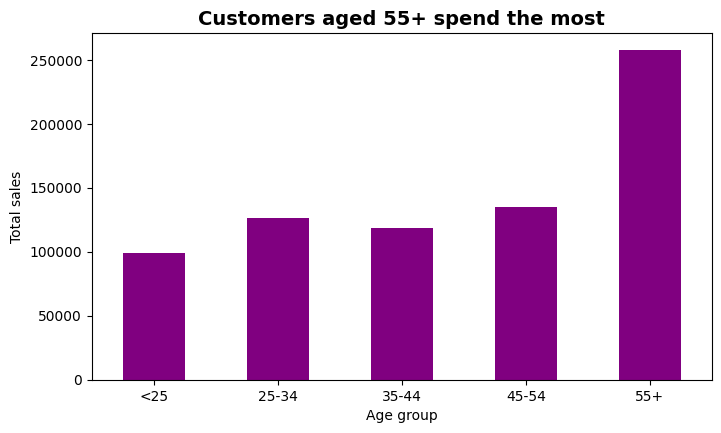

In [11]:
df['age_group'] = pd.cut(df['age'], [0,25,35,45,55,100],
                         labels=['<25','25-34','35-44','45-54','55+'])
s = df.groupby("age_group", observed=True)["total_sales"].sum()
ax = s.plot(kind="bar", figsize=(8, 4.5),
            color="Purple")
plt.title("Customers aged 55+ spend the most", fontsize=14, fontweight="bold")
plt.xlabel("Age group"); plt.ylabel("Total sales"); plt.xticks(rotation=0)
plt.show()

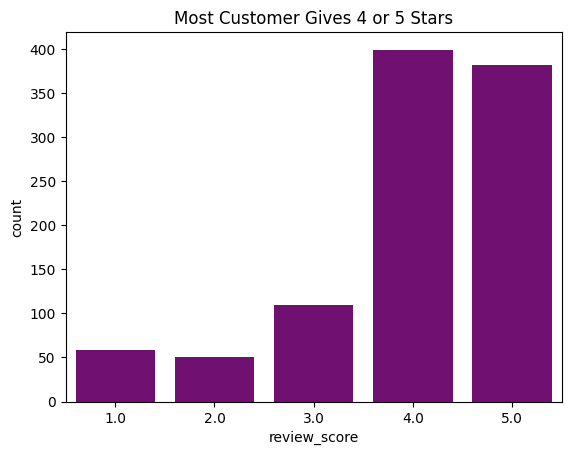

In [12]:
#3 1 star customers spend the least
#average order value by review score
sns.countplot(x='review_score',data=df,color='Purple');
plt.title("Most Customer Gives 4 or 5 Stars")
plt.show()

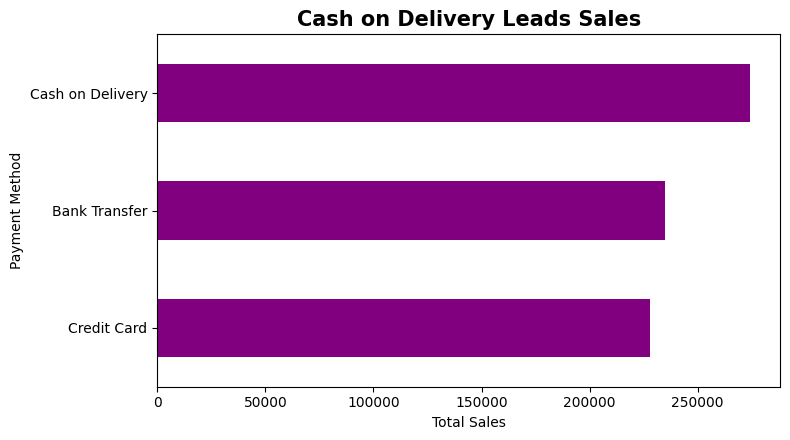

In [13]:
#cash on delivery leads sales


ax = df.groupby('payment_method')['total_sales'].sum().sort_values().plot(
    kind='barh', figsize=(8,4.5), color="Purple")

ax.set_title("Cash on Delivery Leads Sales", fontsize=15, fontweight='bold')
ax.set_xlabel("Total Sales")
ax.set_ylabel("Payment Method")
plt.tight_layout()
plt.show()

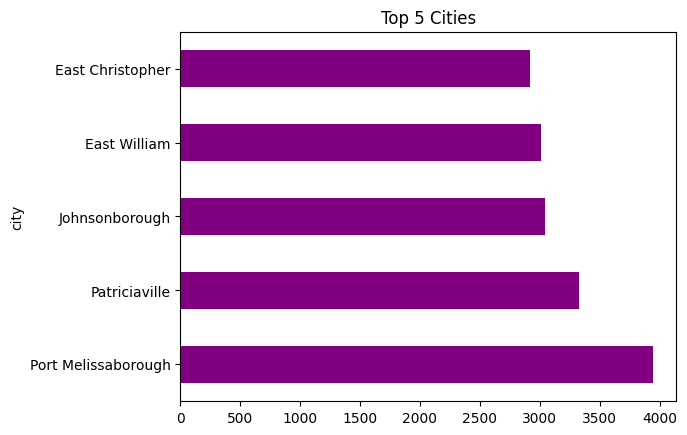

In [14]:
#No single city dominates
#Top 10 Cities by sales (about 2% of revenue combined)
df.groupby('city')['total_sales'].sum().nlargest(5).plot(kind='barh', color="Purple")
plt.title("Top 5 Cities")
plt.show()

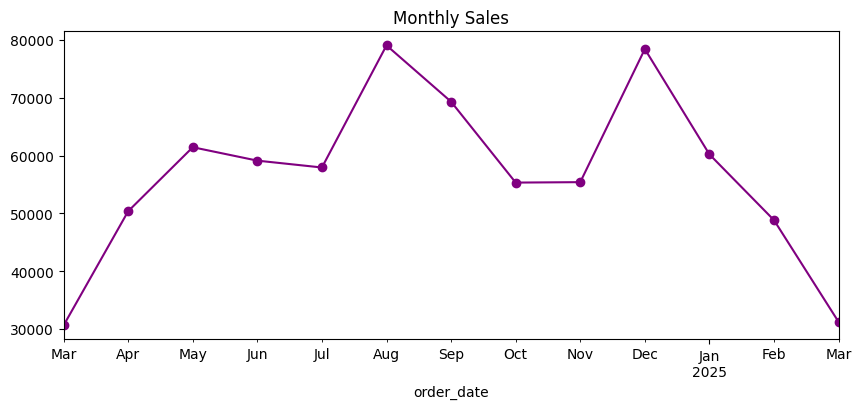

In [15]:
df.groupby(df['order_date'].dt.to_period('M'))['total_sales'].sum().plot(figsize=(10,4), marker='o',color="Purple")
plt.title('Monthly Sales'); plt.show()


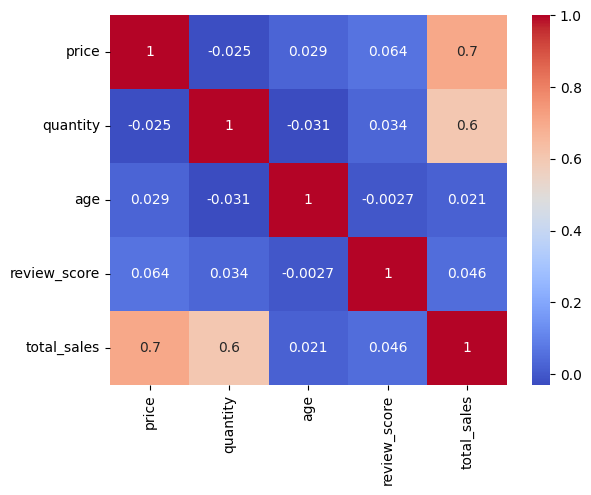

In [16]:
sns.heatmap(df[['price','quantity','age','review_score','total_sales']].corr(), annot=True, cmap='coolwarm')
plt.show()

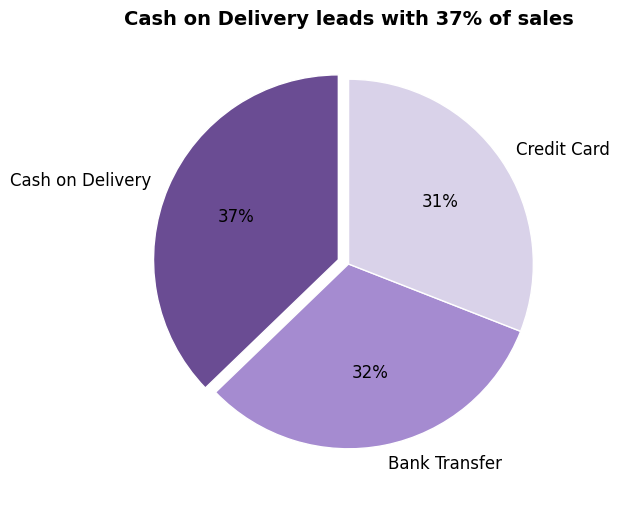

In [17]:
colours = ["#6a4c93", "#a58bd0", "#d9d2e9"]

s = df.groupby("payment_method")["total_sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(6, 6))
plt.pie(s, labels=s.index, autopct="%1.0f%%", startangle=90,
        colors=colours, explode=[0.06, 0, 0],
        textprops={"fontsize": 12},
        wedgeprops={"edgecolor": "white"})
plt.title("Cash on Delivery leads with 37% of sales", fontsize=14, fontweight="bold")
plt.show()

In [18]:
print("Total sales:", df['total_sales'].sum())
print("Avg order value:", df['total_sales'].mean())
print("Avg review score:", df['review_score'].mean())

print(df.groupby('gender')['total_sales'].mean())
print(df.groupby('payment_method')['total_sales'].sum().sort_values(ascending=False))
print(df.groupby('city')['total_sales'].sum().nlargest(5))
print(df.groupby('month')['total_sales'].sum().idxmax(), "= peak month")
print(df.groupby('weekday')['total_sales'].sum().idxmax(), "= peak weekday")
print(df.groupby('review_score')['total_sales'].mean())



Total sales: 737326.8800000001
Avg order value: 737.3268800000001
Avg review score: 3.994
gender
F    753.985568
M    724.237911
Name: total_sales, dtype: float64
payment_method
Cash on Delivery    274375.64
Bank Transfer       234853.69
Credit Card         228097.55
Name: total_sales, dtype: float64
city
Port Melissaborough    3941.29
Patriciaville          3324.10
Johnsonborough         3045.09
East William           3011.36
East Christopher       2919.20
Name: total_sales, dtype: float64
8 = peak month
Friday = peak weekday
review_score
1.0    602.612712
2.0    755.267843
3.0    762.121560
4.0    724.201328
5.0    762.373010
Name: total_sales, dtype: float64
